# How Much Could This Portfolio Lose Tomorrow?
### Monte Carlo Value-at-Risk with historical vs. VIX-implied volatility, backtested on S&P 500 stocks (2016–2024)

*Simulation Applications (QFGB-8925), Fordham University, rebuilt as a portfolio project using Wharton Research Data Services (WRDS).*

---

**The question.** Banks and fund managers forecast "how much could we lose tomorrow?" every day and hold cash against the answer. The forecast depends heavily on one input, **volatility** (how much prices swing). We can estimate it by **looking backwards** (how much prices moved over the past year) or by **looking forwards** (what option prices say traders expect, summarised by the VIX "fear index"). This notebook asks: *which approach gives forecasts that are right as often as they promise, and how much does the choice change the answer?*

**Two risk measures used throughout**

* **Value-at-Risk (VaR), 99%**: a loss that should be exceeded on only **1 day in 100**. "There is a 99% chance we will not lose more than 3% tomorrow."
* **Expected Shortfall (ES), 99%**: the **average loss on those worst 1-in-100 days**, i.e. how bad the bad days are.

**How this notebook is organised.** Each section explains *what* we do and *why*. Modelling choices are marked **Decision** so the reasoning is easy to follow.

| § | Section | What happens |
|---|---|---|
| 1 | Setup | Settings and the reasoning behind each one |
| 2 | Getting the data | Download from WRDS (CRSP stock and index data, Cboe VIX) and cache locally |
| 3 | Cleaning | Align stock returns, index returns and the VIX; check coverage |
| 4 | Exploring the data | Six findings that shape the model design |
| 5 | The Monte Carlo engine | Build one forecast step by step, with checks |
| 6 | The backtest | ~225,000 daily forecasts per model, scored against reality |
| 7 | Results | Which model was right, when models fail, and the capital cost |
| 8 | Is the simulation accurate? | Convergence and variance reduction |
| 9 | Conclusions | Findings, limitations, next steps |

**To run it:** set `DATA_SOURCE` in §1. `"wrds"` needs a WRDS account with CRSP and Cboe (you'll be asked for your password and a Duo approval once; data is then cached in `data/`). `"synthetic"` runs everything on made-up data with the same structure, so anyone can reproduce the pipeline. A full run takes about 10 minutes.

## 1. Setup

### 1.1 Libraries

In [1]:
import os
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 140, "display.max_columns", 20)

### 1.2 Data source and folders

Raw data is cached in `data/` and outputs (figures, summary tables) go to `results/`.

In [2]:
# "wrds" or "synthetic" (an environment variable can override it)
DATA_SOURCE = os.environ.get("DATA_SOURCE", "wrds")

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT / "data" / ("wrds" if DATA_SOURCE == "wrds" else "synthetic")
RESULTS = PROJECT / "results" / ("" if DATA_SOURCE == "wrds" else "synthetic")
FIGS = RESULTS / "figures"
for folder in (DATA_DIR, FIGS):
    folder.mkdir(parents=True, exist_ok=True)

print(f"Data source: {DATA_SOURCE}")

Data source: wrds


### 1.3 Study settings

**Decisions behind the settings**

* **Period 2015–2024.** This covers calm markets (2017, 2019, 2023–24), a sudden crash (COVID, March 2020) and a slow bear market (2022), so the models are tested in every kind of weather. 2015 is used only as look-back history; forecasts start in January 2016.
* **100 random five-stock portfolios per year.** A risk model should work for *any* portfolio, not one hand-picked basket. Redrawing each January from the stocks in the S&P 500 *on that day* gives 900 portfolio-years. Five stocks is small enough that individual stocks matter, which makes the test harder than for a diversified index.
* **One year (252 trading days) of history** for volatility and correlations: the industry-standard minimum (Basel requires at least one year).
* **EWMA decay λ = 0.94**: the RiskMetrics standard for daily data. Yesterday's move gets weight 6%, and the weight halves roughly every 11 days.
* **10,000 simulated paths per forecast.** Section 8 shows this gives a 99% VaR accurate to a few hundredths of a percentage point, small next to the differences between models.

In [3]:
DATA_START, DATA_END = "2015-01-01", "2024-12-31"
FIRST_TEST_YEAR = 2016

N_PORTFOLIOS = 100        # random portfolios drawn each January
N_STOCKS = 5              # stocks per portfolio, equally weighted
LOOKBACK = 252            # trading days of history
EWMA_LAMBDA = 0.94        # RiskMetrics decay factor
HS_WINDOW = 250           # days replayed by historical simulation
LEVELS = (0.95, 0.99)     # VaR / ES confidence levels
N_PATHS = 10_000          # Monte Carlo scenarios per forecast
SEED = 20260223

### 1.4 Model names, colours and chart style

Each model keeps the same colour in every chart.

In [4]:
MODELS = {
    "hist": "Historical vol (normal)",
    "ewma": "EWMA vol (normal)",
    "vix": "VIX-scaled vol (normal)",
    "vix_t": "VIX-scaled vol (fat-tailed t)",
    "hs": "Historical simulation",
}
COLORS = {"hist": "#2a78d6", "ewma": "#eb6834", "vix": "#1baf7a", "vix_t": "#eda100", "hs": "#e87ba4"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

In [5]:
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "lines.linewidth": 2,
})


def save(fig, name):
    # save a figure to results/figures and show it
    fig.savefig(FIGS / f"{name}.png", facecolor="white")
    plt.show()

## 2. Getting the data from WRDS

| Dataset (WRDS) | What we take | Why |
|---|---|---|
| **CRSP daily stock file** | Daily total returns (dividends included) for every stock that was ever in the S&P 500 | The outcomes we forecast, and the history behind every model |
| **CRSP S&P 500 constituents** | Start and end date of every company's index membership | Lets us use the index *as it was at the time* |
| **CRSP daily index file** | Daily return of the S&P 500 index | The index's own realised volatility, the like-for-like partner for the VIX |
| **Cboe (via WRDS)** | Daily VIX | The market's forward-looking volatility forecast |

**Decision: CRSP instead of Yahoo Finance.** The course version used Yahoo Finance and *today's* S&P 500 list from Wikipedia. Companies that crashed, were acquired or were dropped from the index were therefore missing, and they are exactly the risky ones (*survivorship bias*). CRSP's membership history fixes this.

**Decision: the VIX as the forward-looking input, compared like with like.** The VIX is the market's 30-day volatility forecast for the **S&P 500 index**, read from index option prices. The course version divided it by the volatility of **individual stocks**, which mixes up two different things (§4.5). Here the VIX is compared with the **index's own** realised volatility, and that ratio is used to scale each stock's volatility. Stock-by-stock implied volatility (OptionMetrics) would be a natural refinement, but it is not part of this WRDS subscription; §9 discusses it.

**Licensing note:** raw WRDS data must not be published, so `data/` is excluded from git.

### 2.1 Which WRDS tables to use

WRDS has two CRSP formats: legacy (`crsp.dsf`, frozen at end-2024) and the newer CIZ (`crsp.dsf_v2`). We list both and use whichever the account has.

In [6]:
# (library, table, start/date column, end/value column, [name column])
CRSP_FORMATS = {
    "legacy": {"dsf": ("crsp", "dsf", "date", "ret"),
               "sp500": ("crsp", "dsp500list", "start", "ending"),
               "names": ("crsp", "stocknames", "namedt", "nameenddt", "comnam"),
               "index": ("crsp", "dsi", "date", "sprtrn")},
    "ciz": {"dsf": ("crsp", "dsf_v2", "dlycaldt", "dlyret"),
            "sp500": ("crsp", "dsp500list_v2", "mbrstartdt", "mbrenddt"),
            "names": ("crsp", "stksecurityinfohist", "secinfostartdt", "secinfoenddt", "securitynm"),
            "index": ("crsp", "dsi", "date", "sprtrn")},
}
VIX_TABLE = ("cboe", "cboe")
FILES = ["crsp_returns", "sp500_membership", "names", "index_returns", "vix"]

In [7]:
def detect_tables(db):
    # find which CRSP format this account can see, and check the VIX table is there
    seen = {}

    def has(lib, tbl):
        if lib not in seen:
            try:
                seen[lib] = set(db.list_tables(library=lib))
            except Exception:
                seen[lib] = set()
        return tbl in seen[lib]

    fmt = next((f for f, t in CRSP_FORMATS.items() if all(has(v[0], v[1]) for v in t.values())), None)
    print("CRSP format:", fmt, "| VIX table available:", has(*VIX_TABLE))
    assert fmt and has(*VIX_TABLE), "WRDS subscription is missing CRSP or Cboe"
    return fmt

### 2.2 CRSP: index membership, daily returns and names

We download returns for every stock that was in the S&P 500 at **any** point in the window, not just today's members.

In [8]:
def fetch_crsp(db, fmt):
    t = CRSP_FORMATS[fmt]
    lib, tbl, s_col, e_col = t["sp500"]
    in_window = f"{e_col} >= '{DATA_START}' and {s_col} <= '{DATA_END}'"
    universe = f"select distinct permno from {lib}.{tbl} where {in_window}"

    members = db.raw_sql(
        f"select permno, {s_col} as start, {e_col} as ending from {lib}.{tbl} where {in_window}",
        date_cols=["start", "ending"])

    dlib, dtbl, d_col, r_col = t["dsf"]
    returns = db.raw_sql(
        f"select a.permno, a.{d_col} as date, a.{r_col} as ret "
        f"from {dlib}.{dtbl} a join ({universe}) b on a.permno = b.permno "
        f"where a.{d_col} between '{DATA_START}' and '{DATA_END}'",
        date_cols=["date"])
    return members, returns, universe

In [9]:
def fetch_names(db, fmt, universe, members):
    # tickers are only used as labels, so a failure here is not fatal
    nlib, ntbl, _, ne_col, nm_col = CRSP_FORMATS[fmt]["names"]
    try:
        names = db.raw_sql(
            f"select permno, ticker, {nm_col} as company, {ne_col} as name_end "
            f"from {nlib}.{ntbl} where permno in ({universe})", date_cols=["name_end"])
        return names.sort_values("name_end").groupby("permno").tail(1)[["permno", "ticker", "company"]]
    except Exception as exc:
        print("company names unavailable:", exc)
        return pd.DataFrame({"permno": members["permno"].unique(), "ticker": "", "company": ""})

### 2.3 The S&P 500 index return and the VIX

In [10]:
def fetch_index_and_vix(db, fmt):
    lib, tbl, d_col, r_col = CRSP_FORMATS[fmt]["index"]
    index_returns = db.raw_sql(
        f"select {d_col} as date, {r_col} as ret from {lib}.{tbl} "
        f"where {d_col} between '{DATA_START}' and '{DATA_END}'", date_cols=["date"])
    vix = db.raw_sql(
        f"select date, vix from {VIX_TABLE[0]}.{VIX_TABLE[1]} "
        f"where date between '{DATA_START}' and '{DATA_END}' and vix is not null", date_cols=["date"])
    return index_returns.astype({"ret": float}), vix.astype({"vix": float})

### 2.4 Download once, then cache

In [11]:
def download_from_wrds():
    import wrds
    db = wrds.Connection(wrds_username=os.environ.get("WRDS_USERNAME") or None)
    try:
        fmt = detect_tables(db)
        members, returns, universe = fetch_crsp(db, fmt)
        names = fetch_names(db, fmt, universe, members)
        index_returns, vix = fetch_index_and_vix(db, fmt)
    finally:
        db.close()

    out = {
        "crsp_returns": returns.dropna(subset=["ret"]).astype({"permno": int, "ret": float}),
        "sp500_membership": members.astype({"permno": int}),
        "names": names.astype({"permno": int}),
        "index_returns": index_returns,
        "vix": vix,
    }
    for name, df in out.items():
        df.to_parquet(DATA_DIR / f"{name}.parquet", index=False)
        print(f"saved {name}: {len(df):,} rows")

### 2.5 Synthetic data (only used when `DATA_SOURCE = "synthetic"`)

A made-up market with the same file layout: one common market factor, volatility that comes in waves, fat-tailed shocks, a crash in March 2020, one stock delisted in mid-2021, an index that follows the market factor, and a VIX equal to the true market volatility × 1.15 plus noise.

In [12]:
def synthetic_market(rng, dates, n_stocks, nu=5.0):
    # market volatility follows a GARCH process; the 2020 crash triples it
    T = len(dates)
    boost = np.where((dates >= "2020-02-24") & (dates <= "2020-04-30"), 3.0, 1.0)
    m_var, m_ret = np.empty(T), np.empty(T)
    m_var[0] = 0.009 ** 2
    for t in range(T):
        if t:
            m_var[t] = 1.6e-6 + 0.08 * (m_ret[t - 1] / boost[t - 1]) ** 2 + 0.90 * m_var[t - 1]
        m_ret[t] = np.sqrt(m_var[t]) * boost[t] * rng.standard_t(nu) * np.sqrt((nu - 2) / nu)
    m_vol = np.sqrt(m_var) * boost

    beta = rng.uniform(0.6, 1.5, n_stocks)
    idio_vol = rng.uniform(0.010, 0.022, n_stocks)
    idio = rng.standard_t(nu, (T, n_stocks)) * np.sqrt((nu - 2) / nu) * idio_vol
    log_ret = m_ret[:, None] * beta + idio
    true_vol = np.sqrt((m_vol[:, None] * beta) ** 2 + idio_vol ** 2)
    return log_ret, true_vol, m_vol

In [13]:
def make_synthetic(n_stocks=150, n_members=120, seed=7):
    rng = np.random.default_rng(seed)
    dates = pd.bdate_range(DATA_START, DATA_END)
    log_ret, _, m_vol = synthetic_market(rng, dates, n_stocks)
    permnos = np.arange(10001, 10001 + n_stocks)

    ret = pd.DataFrame(np.expm1(log_ret), index=dates, columns=permnos)
    ret.loc["2021-06-15":, permnos[3]] = np.nan                         # a delisting
    index_ret = np.expm1(log_ret[:, :n_members].mean(axis=1))
    vix = 100 * m_vol * 1.15 * np.sqrt(252) * np.exp(rng.normal(0, 0.05, len(dates)))

    spells = [(p, dates[0], dates[-1]) for p in permnos[:n_members]]
    for k, p in enumerate(permnos[n_members:]):                          # stocks rotating in and out
        start = dates[(k * 97) % (len(dates) - 300)]
        spells.append((p, start, start + pd.DateOffset(days=700)))

    def to_long(df, col):
        return df.stack().rename(col).rename_axis(["date", "permno"]).reset_index()

    to_long(ret, "ret").to_parquet(DATA_DIR / "crsp_returns.parquet", index=False)
    pd.DataFrame(spells, columns=["permno", "start", "ending"]).to_parquet(
        DATA_DIR / "sp500_membership.parquet", index=False)
    pd.DataFrame({"permno": permnos, "ticker": [f"S{p}" for p in permnos], "company": ""}).to_parquet(
        DATA_DIR / "names.parquet", index=False)
    pd.DataFrame({"date": dates, "ret": index_ret}).to_parquet(DATA_DIR / "index_returns.parquet", index=False)
    pd.DataFrame({"date": dates, "vix": vix}).to_parquet(DATA_DIR / "vix.parquet", index=False)

### 2.6 Load the data

In [14]:
if all((DATA_DIR / f"{f}.parquet").exists() for f in FILES):
    print("Using cached data in", DATA_DIR)
elif DATA_SOURCE == "wrds":
    download_from_wrds()
else:
    make_synthetic()

raw = {f: pd.read_parquet(DATA_DIR / f"{f}.parquet") for f in FILES}
for name, df in raw.items():
    print(f"{name:18s} {len(df):>10,} rows   columns: {list(df.columns)}")

Using cached data in /Users/a65911/Desktop/Fordham/Sem 2 syllabus/Simulation Applications - EXAMS/Project/Fordham-Simulation-Applications/portfolio-var-volatility-regimes/data/wrds
crsp_returns        1,585,984 rows   columns: ['permno', 'date', 'ret']
sp500_membership          741 rows   columns: ['permno', 'start', 'ending']
names                     736 rows   columns: ['permno', 'ticker', 'company']
index_returns           2,516 rows   columns: ['date', 'ret']
vix                     2,535 rows   columns: ['date', 'vix']


## 3. Cleaning and aligning

We reshape everything into **date × stock grids** (rows = trading days, columns = stocks) so that "stock *j* on day *t*" is one lookup.

**Decision: missing returns are never filled in.** Filling a gap with the previous price invents a day with a 0% return, which makes stocks look calmer and less correlated than they are. Instead, a portfolio is skipped on any day one of its stocks has no data, and we count how often that happens.

### 3.1 Returns grid

In [15]:
ret_w = raw["crsp_returns"].pivot_table(index="date", columns="permno", values="ret").sort_index()
ret_w = ret_w.where(ret_w > -1)        # guard against CRSP's negative missing-value codes

dates = pd.DatetimeIndex(ret_w.index)
permnos = ret_w.columns.to_numpy()
print(f"{len(dates):,} trading days x {len(permnos):,} stocks "
      f"({dates[0].date()} to {dates[-1].date()})")

2,516 trading days x 736 stocks (2015-01-02 to 2024-12-31)


### 3.2 The index and the VIX

**Decision: VIX gaps of up to 5 trading days are carried forward.** The VIX and CRSP calendars occasionally differ by a day (e.g. holidays), and a few-days-old VIX is still informative.

In [16]:
index_ret = raw["index_returns"].set_index("date")["ret"].reindex(dates)
vix = (raw["vix"].set_index("date")["vix"] / 100).reindex(dates).ffill(limit=5)    # percent -> decimal
print(f"Index return missing on {int(index_ret.isna().sum())} days; VIX missing on {int(vix.isna().sum())} days")
print(f"VIX range: {100 * vix.min():.1f} to {100 * vix.max():.1f} (median {100 * vix.median():.1f})")

Index return missing on 0 days; VIX missing on 0 days
VIX range: 9.1 to 82.7 (median 16.3)


### 3.3 The VIX multiplier

The forward-looking models need one number per day: **how much more (or less) turbulent does the options market expect the index to be, compared with the past year?**

$$m_t = \frac{\text{VIX}_t}{\text{realised volatility of the S\&P 500 index over the past 252 days}}$$

If $m_t = 1.3$, the market expects the next month to be 30% more volatile than the past year was. The VIX models multiply every stock's historical volatility by $m_t$ and keep the historical correlations.

In [17]:
index_rv = np.log1p(index_ret).rolling(LOOKBACK).std() * np.sqrt(252)     # trailing one-year, annualised
vix_mult = vix / index_rv
print(vix_mult.describe().round(2).to_string())

count    2265.00
mean        1.16
std         0.38
min         0.57
25%         0.89
50%         1.09
75%         1.34
max         4.43


### 3.4 Arrays used by the rest of the notebook

**Decision: log returns for estimation, simple returns for profit and loss.** Log returns add up over time and suit the normal-distribution model. A portfolio's actual gain or loss is the weighted average of the *simple* returns.

In [18]:
R = ret_w.to_numpy(float)          # simple returns (days x stocks)
X = np.log1p(R)                    # log returns
MULT = vix_mult.to_numpy(float)    # VIX multiplier for each day

membership = raw["sp500_membership"]
tickers = dict(zip(raw["names"]["permno"], raw["names"]["ticker"]))

In [19]:
def members_on(date):
    # column positions of the stocks that were in the S&P 500 on `date`
    live = membership[(membership["start"] <= date) & (membership["ending"] >= date)]["permno"]
    return np.flatnonzero(np.isin(permnos, live.unique()))


def usable_stocks(i):
    # index members on day i with a full year of return history
    cols = members_on(dates[i])
    return cols[np.isfinite(X[i - LOOKBACK:i, cols]).all(axis=0)]

## 4. Exploring the data: six findings that shape the models

Before building anything we look at the data. Each finding below leads directly to a design choice.

### 4.1 The index changes a lot, so survivorship bias is real

First: how many companies were in the S&P 500 at each point, and how many we can actually use (a full year of return history).

In [20]:
check_days = np.flatnonzero(dates.year >= FIRST_TEST_YEAR)[::21]      # roughly monthly
universe = pd.DataFrame({
    "in_index": [len(members_on(dates[i])) for i in check_days],
    "usable": [len(usable_stocks(i)) for i in check_days],
}, index=dates[check_days])
print(f"Usable share of index members: {100 * (universe['usable'] / universe['in_index']).mean():.1f}% on average")

Usable share of index members: 99.4% on average


Next: how many companies joined and left the index each year.

In [21]:
m = membership[(membership["ending"] >= DATA_START) & (membership["start"] <= DATA_END)]
turnover = pd.DataFrame({
    "joined": m[m["start"] > dates[0]]["start"].dt.year.value_counts(),
    "left": m[m["ending"] < dates[-1]]["ending"].dt.year.value_counts(),
}).fillna(0).astype(int).sort_index()
turnover.T

,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
joined,29,39,29,28,25,18,19,17,18,17
left,27,38,29,29,24,18,19,19,18,17


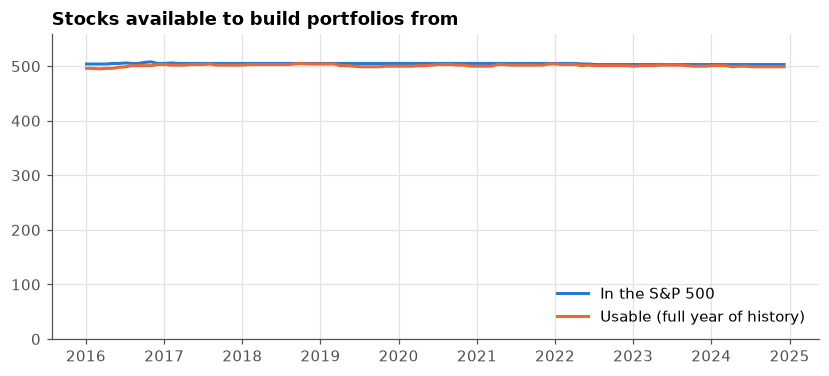

In [22]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(universe.index, universe["in_index"], color=COLORS["hist"], label="In the S&P 500")
ax.plot(universe.index, universe["usable"], color=COLORS["ewma"], label="Usable (full year of history)")
ax.set_ylim(0, universe["in_index"].max() * 1.1)
ax.set_title("Stocks available to build portfolios from")
ax.legend(loc="lower right")
save(fig, "eda_1_universe")

**What this tells us.** Dozens of companies enter and leave the index every year. A study that starts from *today's* list (as the course version did) silently drops every company that left, often after a collapse or takeover, and so understates risk. Here every portfolio is drawn from the index **as it stood on the day of the draw**, and a company's later history (including a delisting) stays in the test.

### 4.2 Extreme days are far more common than a bell curve predicts ("fat tails")

If daily returns followed a normal (bell-curve) distribution, moves beyond 3 standard deviations would happen on 0.27% of days. We measure how often they really happen, scaling each return two ways:
* by the stock's volatility over the **whole period**;
* by its **recent** volatility (EWMA), which asks whether extremes are just normal days in a stormy period.

First, a helper that gives each day's recent (EWMA) volatility as of the day before.

In [23]:
def ewma_vol_path(x, lam=EWMA_LAMBDA, burn_in=20):
    # yesterday's EWMA volatility for every day (days x stocks); missing days carry the old value
    v = np.full_like(x, np.nan)
    v[burn_in] = np.nanvar(x[:burn_in], axis=0)
    for t in range(burn_in + 1, len(x)):
        prev_sq = np.where(np.isfinite(x[t - 1]), x[t - 1] ** 2, v[t - 1])
        v[t] = lam * v[t - 1] + (1 - lam) * prev_sq
    return np.sqrt(v)

In [24]:
well_covered = np.isfinite(X).mean(axis=0) > 0.95

z_static = (X / np.nanstd(X, axis=0))[:, well_covered].ravel()
z_recent = (X / ewma_vol_path(X))[30:, well_covered].ravel()
z_static = z_static[np.isfinite(z_static)]
z_recent = z_recent[np.isfinite(z_recent)]

In [25]:
def tail_stats(z):
    return [100 * np.mean(np.abs(z) > 3), 100 * np.mean(np.abs(z) > 4), stats.kurtosis(z)]

tails = pd.DataFrame(
    [[0.27, 0.0063, 0.0], tail_stats(z_static), tail_stats(z_recent)],
    index=["Normal distribution", "Scaled by whole-period vol", "Scaled by recent (EWMA) vol"],
    columns=["% of days beyond ±3σ", "% of days beyond ±4σ", "Excess kurtosis"])
tails.round(3)

,% of days beyond ±3σ,% of days beyond ±4σ,Excess kurtosis
Normal distribution,0.270,0.006,0.000
Scaled by whole-period vol,1.439,0.672,16.889
Scaled by recent (EWMA) vol,1.610,0.675,24.907


A Student-t distribution has one extra parameter, ν (degrees of freedom): the smaller ν, the fatter the tails. We fit it to the recent-volatility-scaled returns.

In [26]:
sample = np.random.default_rng(0).choice(z_recent, 200_000)
nu_hat = float(np.clip(stats.t.fit(sample, floc=0)[0], 3, 30))
print(f"Fitted tail parameter ν = {nu_hat:.1f}  (a normal distribution corresponds to ν = ∞)")

Fitted tail parameter ν = 4.2  (a normal distribution corresponds to ν = ∞)


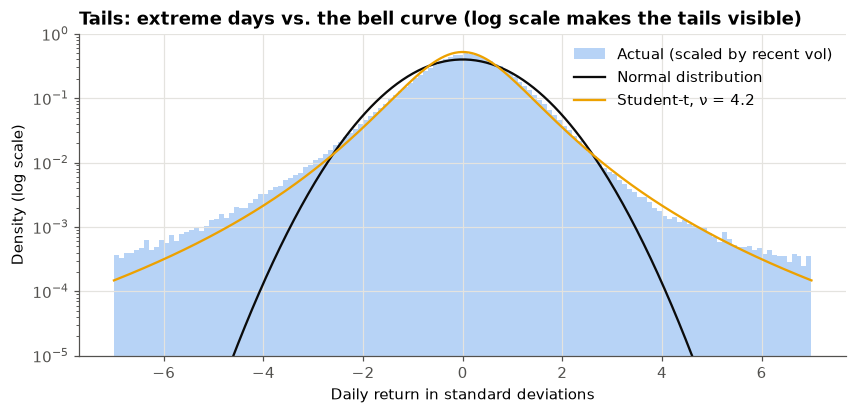

In [27]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(z_recent, bins=np.linspace(-7, 7, 141), density=True, color="#b7d3f6", label="Actual (scaled by recent vol)")
xs = np.linspace(-7, 7, 400)
ax.plot(xs, stats.norm.pdf(xs), color=INK, lw=1.5, label="Normal distribution")
sd_t = np.sqrt(nu_hat / (nu_hat - 2))                  # rescale t to unit variance
ax.plot(xs, stats.t.pdf(xs * sd_t, nu_hat) * sd_t, color=COLORS["vix_t"], lw=1.5, label=f"Student-t, ν = {nu_hat:.1f}")
ax.set_yscale("log")
ax.set_ylim(1e-5, 1)
ax.set_xlabel("Daily return in standard deviations")
ax.set_ylabel("Density (log scale)")
ax.set_title("Tails: extreme days vs. the bell curve (log scale makes the tails visible)")
ax.legend()
save(fig, "eda_2_fat_tails")

**What this tells us.** Moves beyond 3 standard deviations happen several times more often than a bell curve allows, whichever way we scale the returns. The extremes survive scaling by *recent* volatility, so fat tails are a genuine feature and not only a side-effect of changing volatility. A Student-t distribution (orange) fits the tails far better than the normal curve.

**Decision:** include a **fat-tailed (Student-t) model**, with ν re-estimated each January from the previous year's returns *after* scaling by recent volatility. That way we don't double-count the effect of changing volatility.

### 4.3 Volatility comes in waves ("volatility clustering")

Big moves tend to follow big moves. We look at an equal-weighted average of all stocks trading each day: its rolling one-month volatility, and how strongly today's move predicts the next 20 days.

In [28]:
avg_stock = pd.Series(np.nanmean(R, axis=1), index=dates)     # equal-weighted average return
roll_vol = avg_stock.rolling(21).std() * np.sqrt(252) * 100

lags = np.arange(1, 21)
acf_return = [avg_stock.autocorr(k) for k in lags]
acf_size = [avg_stock.abs().autocorr(k) for k in lags]

print(f"Calmest month: {roll_vol.min():.0f}% volatility.  Most turbulent: {roll_vol.max():.0f}% "
      f"(around {roll_vol.idxmax().date()})")

Calmest month: 4% volatility.  Most turbulent: 108% (around 2020-04-06)


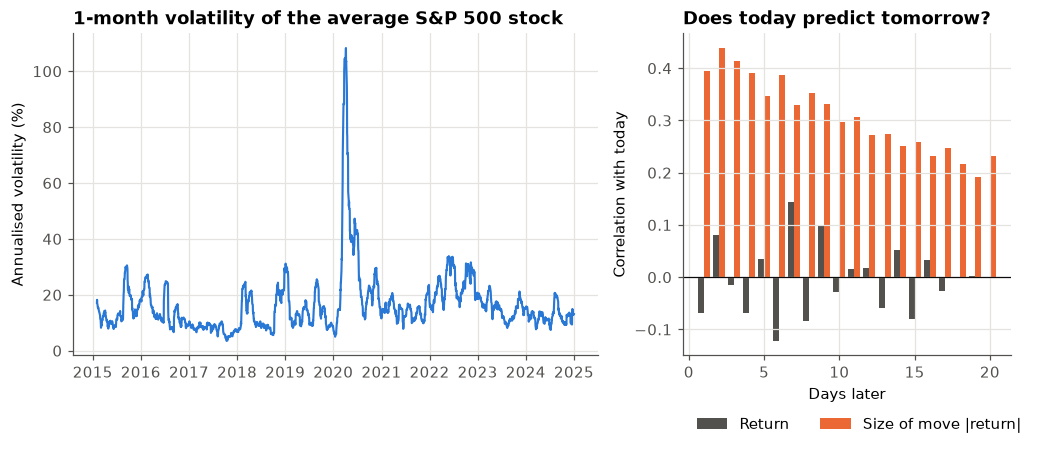

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})

axes[0].plot(roll_vol.index, roll_vol, color=COLORS["hist"], lw=1.4)
axes[0].set_ylabel("Annualised volatility (%)")
axes[0].set_title("1-month volatility of the average S&P 500 stock")

axes[1].bar(lags - 0.2, acf_return, 0.4, color=MUTED, label="Return")
axes[1].bar(lags + 0.2, acf_size, 0.4, color=COLORS["ewma"], label="Size of move |return|")
axes[1].axhline(0, color=INK, lw=0.8)
axes[1].set_xlabel("Days later")
axes[1].set_ylabel("Correlation with today")
axes[1].set_title("Does today predict tomorrow?")
axes[1].legend(loc="upper left", bbox_to_anchor=(0, -0.15), ncol=2)
save(fig, "eda_3_clustering")

**What this tells us.** The *direction* of tomorrow's move is close to unpredictable (grey bars near zero), but its *size* is not: a big day today makes big days likely for weeks (orange bars stay positive).

**Decision:** a model that weights the whole past year equally will react slowly. We test two faster alternatives against it: **EWMA**, which weights recent days more, and the **VIX**, which reacts the same day. We also check whether breaches bunch together, the signature of a slow model (Christoffersen test, §7).

### 4.4 What does the VIX say compared with history?

The VIX is the options market's forecast of the index's volatility over the **next** month. We compare it with two things: the index's volatility over the **past** year (what a backward-looking model uses), and what actually happened over the **next** month (what the forecast should predict).

In [30]:
index_log = np.log1p(index_ret)
next_month_rv = index_log[::-1].rolling(21).std()[::-1].shift(-1) * np.sqrt(252)   # days t+1 .. t+21

vix_check = pd.DataFrame({"vix": vix, "past_year_rv": index_rv, "next_month_rv": next_month_rv}).dropna()
vix_check = vix_check[vix_check.index.year >= FIRST_TEST_YEAR]

print(f"Median VIX ÷ next-month realised vol: {(vix_check['vix'] / vix_check['next_month_rv']).median():.2f}"
      "   (above 1 = options price in more risk than then materialises)")
print("How well does each predict next month's volatility? (correlation)")
print(f"  VIX today            : {vix_check['vix'].corr(vix_check['next_month_rv']):.2f}")
print(f"  Past-year volatility : {vix_check['past_year_rv'].corr(vix_check['next_month_rv']):.2f}")

Median VIX ÷ next-month realised vol: 1.39   (above 1 = options price in more risk than then materialises)
How well does each predict next month's volatility? (correlation)
  VIX today            : 0.62
  Past-year volatility : 0.23


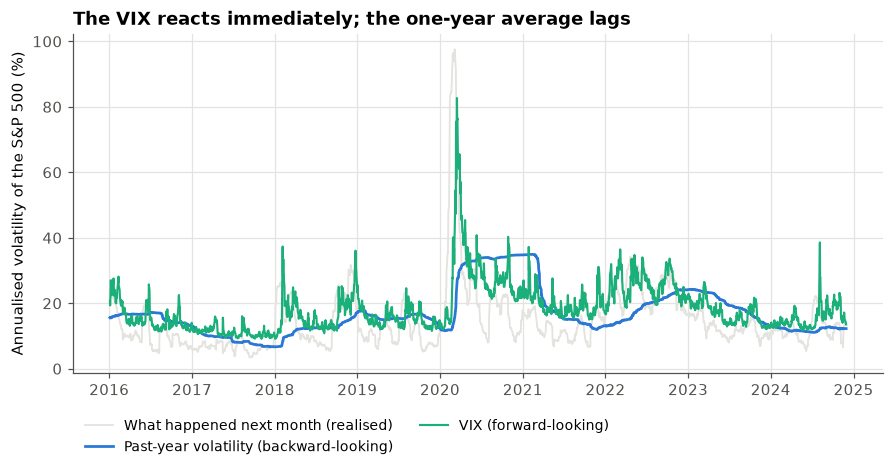

In [31]:
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(vix_check.index, 100 * vix_check["next_month_rv"], color=GRID, lw=1.2, label="What happened next month (realised)")
ax.plot(vix_check.index, 100 * vix_check["past_year_rv"], color=COLORS["hist"], lw=1.8, label="Past-year volatility (backward-looking)")
ax.plot(vix_check.index, 100 * vix_check["vix"], color=COLORS["vix"], lw=1.4, label="VIX (forward-looking)")
ax.set_ylabel("Annualised volatility of the S&P 500 (%)")
ax.set_title("The VIX reacts immediately; the one-year average lags")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), ncol=2, fontsize=9)
save(fig, "eda_4_vix_vs_realised")

**What this tells us.** The one-year average (blue) moves slowly: it barely rises when a crisis starts and stays high for a year after it ends. The VIX (green) jumps at once and falls back quickly, so it tracks next month's actual volatility (grey) much more closely. It also usually sits *above* what follows, because option buyers pay a premium for protection (the "volatility risk premium").

**Decision:** the forward-looking models use $m_t$ = VIX ÷ the index's own past-year volatility (§3.3) to scale every stock's volatility. Options on the index tell us about the whole market, not about how individual stocks move *together*, so correlations still come from the past year.

### 4.5 Discovery: the course version compared an index with single stocks

The course version's multiplier was **VIX ÷ average single-stock volatility**, which came out at 0.53, and it concluded that options priced "about half" the historical risk. But the VIX measures the **S&P 500 index**, and an index of 500 stocks is much calmer than a typical single stock because individual ups and downs cancel out. Dividing one by the other mostly measures diversification. The like-for-like ratio uses the **index's own** history (§3.3).

In [32]:
rows = []
for i in np.arange(LOOKBACK, len(dates), 5):
    cols = members_on(dates[i])
    hist = X[i - LOOKBACK:i, cols]
    stock_vol = hist[:, np.isfinite(hist).all(axis=0)].std(axis=0, ddof=1) * np.sqrt(252)
    rows.append({"date": dates[i], "avg_stock_vol": stock_vol.mean()})
compare = pd.DataFrame(rows).set_index("date")
compare["course_multiplier"] = vix.reindex(compare.index) / compare["avg_stock_vol"]
compare["like_for_like"] = vix_mult.reindex(compare.index)
compare = compare.dropna()
compare.to_csv(RESULTS / "volatility_comparison.csv")

compare[["course_multiplier", "like_for_like"]].describe().loc[["mean", "min", "max"]].round(2).rename(columns={
    "course_multiplier": "Course version: VIX ÷ avg stock vol",
    "like_for_like": "Corrected: VIX ÷ index vol"})

,Course version: VIX ÷ avg stock vol,Corrected: VIX ÷ index vol
mean,0.60,1.16
min,0.38,0.60
max,1.76,3.16


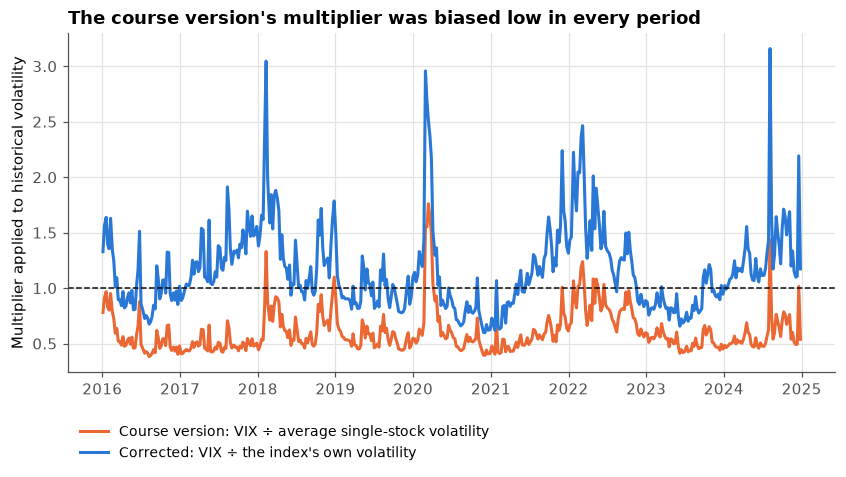

In [33]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(compare.index, compare["course_multiplier"], color=COLORS["ewma"],
        label="Course version: VIX ÷ average single-stock volatility")
ax.plot(compare.index, compare["like_for_like"], color=COLORS["hist"],
        label="Corrected: VIX ÷ the index's own volatility")
ax.axhline(1, color=INK, lw=1, ls="--")
ax.set_ylabel("Multiplier applied to historical volatility")
ax.set_title("The course version's multiplier was biased low in every period")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.12), fontsize=9)
save(fig, "eda_5_original_multiplier")

**What this tells us.** The course version's multiplier sits far below the like-for-like one **in every period**, calm or stormy, because the gap is mostly diversification, not market sentiment. Its headline conclusion, that "historical volatility overstates risk by about 2×", was therefore largely an artefact of comparing an index with single stocks. Correcting it is the main reason for this rebuild.

### 4.6 Correlations jump in a crisis

Diversification works only if stocks don't all fall together. Every 10 trading days we take up to 150 index members and compute their average pairwise correlation over the previous 3 months.

In [34]:
rng_eda = np.random.default_rng(1)
corr_path = {}
for i in np.arange(63, len(dates), 10):
    window = X[i - 63:i, members_on(dates[i])]
    window = window[:, np.isfinite(window).all(axis=0)]
    pick = rng_eda.choice(window.shape[1], min(150, window.shape[1]), replace=False)
    c = np.corrcoef(window[:, pick].T)
    corr_path[dates[i]] = c[np.triu_indices_from(c, 1)].mean()
corr_path = pd.Series(corr_path)

print(f"Typical average correlation: {corr_path.median():.2f}.  "
      f"Peak: {corr_path.max():.2f} on {corr_path.idxmax().date()}")

Typical average correlation: 0.28.  Peak: 0.67 on 2020-03-23


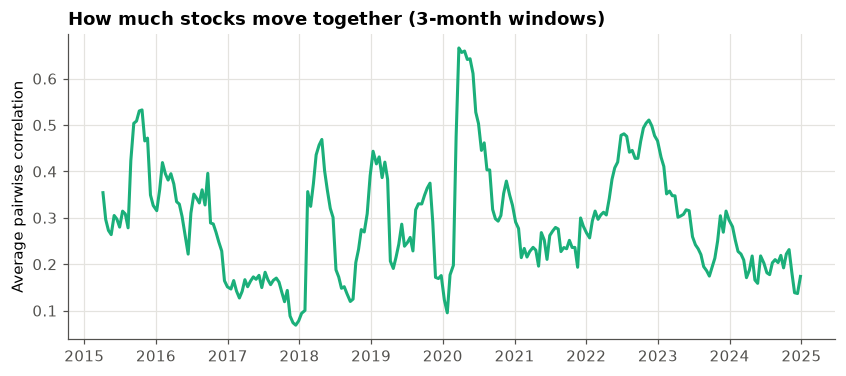

In [35]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(corr_path.index, corr_path, color=COLORS["vix"])
ax.set_ylabel("Average pairwise correlation")
ax.set_title("How much stocks move together (3-month windows)")
save(fig, "eda_6_correlation")

**What this tells us.** In a sell-off stocks fall together: average correlation jumps well above its normal level, and diversification fails just when it is needed. All our models take correlation from the *past year*, so they will under-react to this. That is a known limitation (§9) and one reason to expect more breaches in crisis periods.

### Summary: from findings to design decisions

| Finding | Decision |
|---|---|
| The index turns over every year | Draw portfolios from point-in-time members (CRSP) |
| Fat tails remain after allowing for changing volatility | Add a Student-t model, ν fitted each year |
| Volatility clusters | Compare the slow model (equal-weight year) with faster ones (EWMA, implied) |
| The VIX reacts at once, the one-year average lags; the VIX carries a premium | Scale stock volatility by VIX ÷ index volatility; keep historical correlations |
| Course version compared an index with single stocks | Compare like with like; the course version's 2× gap was mostly an artefact |
| Correlations spike in crises | Flagged as a limitation; watch crisis-year breaches |

## 5. The Monte Carlo engine, built step by step

**The idea.** We can't know tomorrow's return, but we can describe how likely different returns are and **simulate 10,000 possible tomorrows**. Sort them from worst to best. The 100th-worst is the 99% VaR; the average of the 100 worst is the 99% ES.

For one portfolio on one day:

1. **Volatility and correlation.** Put each stock's volatility and the correlations into a *covariance matrix* Σ. The five models differ only in how Σ is built (and model 4 in the shock distribution).
2. **Independent random shocks.** Draw 10,000 × 5 standard normal numbers *z*.
3. **Make them move together.** Cholesky decomposition finds a matrix *L* with Σ = *L Lᵀ*. Then *r = L z* has exactly the covariance Σ, so stocks that tend to move together in reality do so in the simulation.
4. **Fat tails (model 4 only).** Multiply each scenario by $\sqrt{(\nu-2)/\chi^2_\nu}$. This turns normal shocks into Student-t shocks with the same variance but more extreme days.
5. **Portfolio outcome.** Convert log returns to simple returns and average them (equal weights): $R_p = \tfrac{1}{5}\sum_i (e^{r_i}-1)$.
6. **Read off the risk.** VaR = −(1st percentile), ES = −(average below it).

**Decision: zero expected return.** Over one day the average return (~0.03%) is tiny next to volatility (1–2%), and estimating it adds noise. Every model therefore assumes zero drift, the standard choice for daily risk. (The course version's "risk-neutral" variant changed only the drift, which is why it barely moved the results.)

All functions below work on a whole batch of portfolios at once: arrays shaped *(days, portfolios, stocks)* for history and *(portfolios, stocks, stocks)* for covariance matrices.

### 5.1 Three ways to build the covariance matrix

In [36]:
def sample_cov(window):
    # every day of the window counts equally (models 1 and, for correlations, 3-4)
    x = window - window.mean(axis=0)
    return np.einsum("dki,dkj->kij", x, x) / (window.shape[0] - 1)

In [37]:
def ewma_cov(window, lam=EWMA_LAMBDA):
    # recent days count more: weight lam^age, normalised to sum to 1 (model 2)
    weights = lam ** np.arange(window.shape[0] - 1, -1, -1)
    return np.einsum("d,dki,dkj->kij", weights / weights.sum(), window, window)

In [38]:
def vix_cov(cov_hist, multiplier):
    # scale every stock's volatility by the day's VIX multiplier; correlations unchanged (models 3-4)
    return cov_hist * multiplier ** 2

### 5.2 Random shocks

In [39]:
def cholesky(cov):
    # batched Cholesky; nudges the diagonal by a tiny amount if a matrix is borderline
    try:
        return np.linalg.cholesky(cov)
    except np.linalg.LinAlgError:
        n = cov.shape[-1]
        return np.linalg.cholesky(cov + 1e-10 * np.einsum("kii->k", cov)[:, None, None] * np.eye(n))

In [40]:
def normal_shocks(rng, n_paths, n_stocks, antithetic=True):
    # independent standard normals; antithetic = each scenario paired with its mirror image
    if not antithetic:
        return rng.standard_normal((n_paths, n_stocks))
    half = rng.standard_normal((n_paths // 2, n_stocks))
    return np.concatenate([half, -half])


def t_multiplier(rng, n_paths, nu):
    # per-scenario factor that turns normal shocks into unit-variance Student-t shocks
    s = np.sqrt((nu - 2) / rng.chisquare(nu, n_paths // 2))
    return np.concatenate([s, s])

### 5.3 Simulate and read off VaR / ES

In [41]:
def simulate(chol, z, scale=None):
    # simulated one-day simple returns of equal-weight portfolios -> (portfolios, scenarios)
    log_r = z[None] @ np.swapaxes(chol, 1, 2)
    if scale is not None:
        log_r = log_r * scale[None, :, None]
    return np.expm1(log_r).mean(axis=2)

In [42]:
def var_es(port, level):
    # VaR and ES as positive loss fractions, from a (portfolios, scenarios) array
    m = max(int(np.ceil(port.shape[1] * (1 - level))), 1)
    worst = np.partition(port, m - 1, axis=1)[:, :m]
    return -worst.max(axis=1), -worst.mean(axis=1)


def normal_var_es(sigma, level):
    # closed-form answer for a normal distribution, used as a check
    q = stats.norm.ppf(level)
    return sigma * q, sigma * stats.norm.pdf(q) / (1 - level)

### 5.4 Walk-through: one real forecast

The first trading day of 2020, a few weeks before COVID reached markets, and five random stocks from that day's index.

In [43]:
rng = np.random.default_rng(1)
i_demo = int(np.flatnonzero(dates.year == 2020)[0])
demo = rng.choice(usable_stocks(i_demo), N_STOCKS, replace=False)
demo_names = [str(tickers.get(permnos[c], permnos[c])) for c in demo]
window_demo = X[i_demo - LOOKBACK:i_demo, demo][:, None, :]      # one portfolio
print("Forecast for", dates[i_demo].date(), "- portfolio:", ", ".join(demo_names))

Forecast for 2020-01-02 - portfolio: LOW, MXIM, ANSS, UAL, FRT


**Step 1: the ingredients.** Each stock's volatility under the three approaches:

In [44]:
cov_h = sample_cov(window_demo)
cov_e = ewma_cov(window_demo)
cov_v = vix_cov(cov_h, MULT[i_demo - 1])
print(f"VIX multiplier the evening before: {MULT[i_demo - 1]:.2f}")

pd.DataFrame({
    "past-year vol %": 100 * np.sqrt(np.diag(cov_h[0]) * 252),
    "EWMA vol %": 100 * np.sqrt(np.diag(cov_e[0]) * 252),
    "VIX-scaled vol %": 100 * np.sqrt(np.diag(cov_v[0]) * 252),
}, index=demo_names).round(1)

VIX multiplier the evening before: 1.10


,past-year vol %,EWMA vol %,VIX-scaled vol %
LOW,26.3,13.6,29.0
MXIM,27.4,17.8,30.2
ANSS,23.1,15.6,25.5
UAL,23.0,14.2,25.4
FRT,15.1,12.3,16.7


...and how the stocks move together (correlation, from the past year):

In [45]:
sd = np.sqrt(np.diag(cov_h[0]))
pd.DataFrame(cov_h[0] / np.outer(sd, sd), index=demo_names, columns=demo_names).round(2)

,LOW,MXIM,ANSS,UAL,FRT
LOW,1.00,0.34,0.36,0.34,0.17
MXIM,0.34,1.00,0.55,0.49,0.12
ANSS,0.36,0.55,1.00,0.39,0.23
UAL,0.34,0.49,0.39,1.00,0.16
FRT,0.17,0.12,0.23,0.16,1.00


**Steps 2–5: simulate 200,000 possible tomorrows under each model.** The same random shocks are used for every model, so differences come from the models alone.

In [46]:
z = normal_shocks(rng, 200_000, N_STOCKS)
scale = t_multiplier(rng, 200_000, nu_hat)

sims = {
    "hist": simulate(cholesky(cov_h), z)[0],
    "ewma": simulate(cholesky(cov_e), z)[0],
    "vix": simulate(cholesky(cov_v), z)[0],
    "vix_t": simulate(cholesky(cov_v), z, scale)[0],
}

**Check 1:** the correlated shocks should reproduce the covariance matrix we fed in.

In [47]:
simulated_cov = np.cov((z @ cholesky(cov_h)[0].T).T)
error = np.abs(simulated_cov - cov_h[0]).max() / cov_h[0].diagonal().max()
print(f"Largest covariance error: {error:.2%} of the largest variance")
assert error < 0.03

Largest covariance error: 0.36% of the largest variance


**Check 2:** for the normal model there is a textbook formula, and the simulation should land close to it. A small gap is expected because the formula treats returns as log returns and the simulation as simple returns.

In [48]:
w = np.full(N_STOCKS, 1 / N_STOCKS)
formula_var, formula_es = normal_var_es(np.sqrt(w @ cov_h[0] @ w), 0.99)
sim_var, sim_es = var_es(sims["hist"][None], 0.99)
print(f"99% VaR: simulated {100 * sim_var[0]:.3f}%  vs formula {100 * formula_var:.3f}%")
print(f"99% ES : simulated {100 * sim_es[0]:.3f}%  vs formula {100 * formula_es:.3f}%")
assert abs(sim_var[0] / formula_var - 1) < 0.05

99% VaR: simulated 2.291%  vs formula 2.327%
99% ES : simulated 2.627%  vs formula 2.666%


**Step 6: read off the risk.** Each model's forecast for this portfolio on this day:

In [49]:
forecast = {}
for k, sim in sims.items():
    row = {}
    for lv in LEVELS:
        v, e = var_es(sim[None], lv)
        row[f"{int(lv * 100)}% VaR"], row[f"{int(lv * 100)}% ES"] = 100 * v[0], 100 * e[0]
    forecast[MODELS[k]] = row
pd.DataFrame(forecast).T.round(2)

,95% VaR,95% ES,99% VaR,99% ES
Historical vol (normal),1.62,2.03,2.29,2.63
EWMA vol (normal),0.92,1.15,1.30,1.49
VIX-scaled vol (normal),1.79,2.24,2.52,2.89
VIX-scaled vol (fat-tailed t),1.64,2.42,2.84,3.88


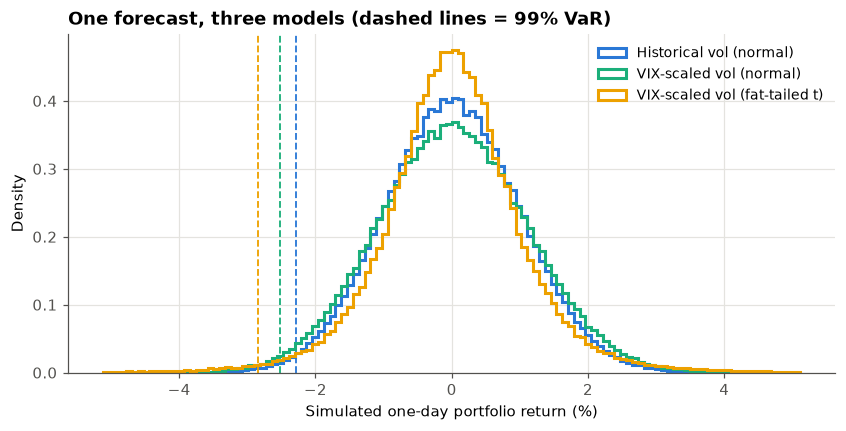

In [50]:
lim = 1.8 * max(var_es(s[None], 0.99)[0][0] for s in sims.values())
bins = np.linspace(-100 * lim, 100 * lim, 121)

fig, ax = plt.subplots(figsize=(9, 4))
for k in ("hist", "vix", "vix_t"):
    ax.hist(100 * sims[k], bins=bins, histtype="step", lw=2, density=True, color=COLORS[k], label=MODELS[k])
    ax.axvline(-100 * var_es(sims[k][None], 0.99)[0][0], color=COLORS[k], ls="--", lw=1.2)
ax.set_xlabel("Simulated one-day portfolio return (%)")
ax.set_ylabel("Density")
ax.set_title("One forecast, three models (dashed lines = 99% VaR)")
ax.legend(fontsize=9)
save(fig, "engine_one_day_distribution")

The engine passes both checks, and the models clearly disagree about the same portfolio on the same day. Only checking thousands of forecasts against what actually happened can tell us which one to trust.

## 6. The backtest: forecasting every day, 2016–2024

For each trading day *t*, every model forecasts day *t*'s risk using **only data up to the close of day *t − 1***. Then we record what actually happened on day *t*.

| Model | Volatility | Shocks | Role |
|---|---|---|---|
| Historical vol | Past 252 days, equal weights | Normal | Textbook approach (course version) |
| EWMA vol | Past days, weight decaying 6% a day | Normal | Industry standard (RiskMetrics) |
| VIX-scaled vol | Past-year vol × (VIX ÷ index's past-year vol) | Normal | Forward-looking |
| VIX-scaled vol, fat-tailed | Same | Student-t, ν fitted each year | Forward-looking + fat tails |
| Historical simulation | — (replays the last 250 actual days) | Empirical | Most common method at banks |

**Decision: common random numbers.** On each day, all models and portfolios use the *same* 10,000 random shocks. Differences between models then reflect the models, not simulation luck.

**Decision: skip, don't patch.** If a stock in a portfolio has no return on a day (e.g. after a delisting), or the VIX is missing, that portfolio-day is skipped and counted.

### 6.1 Building blocks

The tail parameter ν for the fat-tailed model, re-fitted each January from the past year:

In [51]:
def fit_t_dof(cols, i0):
    # tail thickness from last year's returns scaled by their own recent (EWMA) volatility
    x = X[i0 - LOOKBACK:i0, cols]
    z = (x / ewma_vol_path(x))[21:].ravel()
    return float(np.clip(stats.t.fit(z[np.isfinite(z)], floc=0)[0], 3, 30))

Drawing the year's 100 random portfolios from that day's usable index members:

In [52]:
def draw_portfolios(rng, i0, n_portfolios):
    pool = usable_stocks(i0)
    return np.array([rng.choice(pool, N_STOCKS, replace=False) for _ in range(n_portfolios)]), pool

One day's forecasts for all portfolios and all five models. Portfolios with missing data that day get a harmless placeholder so the batch keeps its shape; their rows are dropped at the end.

In [53]:
PLACEHOLDER = 0.01 * np.random.default_rng(0).standard_normal((LOOKBACK, N_STOCKS))


def forecast_one_day(i, idx, nu, rng, n_paths, X, R, MULT):
    window = X[i - LOOKBACK:i][:, idx]          # history up to the close of day t-1
    mult = MULT[i - 1]                          # VIX multiplier at the close of day t-1
    actual = R[i][idx]                          # what happened on day t
    ok = np.isfinite(window).all((0, 2)) & np.isfinite(actual).all(1) & np.isfinite(mult)
    if not ok.any():
        return None, int((~ok).sum())
    window = np.where(ok[None, :, None], window, PLACEHOLDER[:, None, :])

    cov_hist = sample_cov(window)
    chol = {"hist": cholesky(cov_hist),
            "ewma": cholesky(ewma_cov(window)),
            "vix": cholesky(vix_cov(cov_hist, mult))}
    z = normal_shocks(rng, n_paths, N_STOCKS)   # common random numbers for all models
    sims = {"hist": simulate(chol["hist"], z),
            "ewma": simulate(chol["ewma"], z),
            "vix": simulate(chol["vix"], z),
            "vix_t": simulate(chol["vix"], z, t_multiplier(rng, n_paths, nu)),
            "hs": np.expm1(window[-HS_WINDOW:]).mean(axis=2).T}

    out = {"date": dates[i], "portfolio": np.arange(len(idx)), "realized": actual.mean(axis=1)}
    for lv in LEVELS:
        for k, sim in sims.items():
            out[f"var{int(lv * 100)}_{k}"], out[f"es{int(lv * 100)}_{k}"] = var_es(sim, lv)
    return pd.DataFrame(out)[ok], int((~ok).sum())

The full loop: for each year, draw portfolios and fit ν, then forecast every trading day.

In [54]:
def run_backtest(years, n_portfolios=N_PORTFOLIOS, n_paths=N_PATHS, X=X, R=R, MULT=MULT, verbose=True):
    rng = np.random.default_rng(SEED)
    frames, dofs, skipped = [], {}, 0
    for year in years:
        days = np.flatnonzero(dates.year == year)
        idx, pool = draw_portfolios(rng, days[0], n_portfolios)
        dofs[year] = fit_t_dof(pool, days[0])
        tic = time.time()
        for i in days:
            day, n_skip = forecast_one_day(i, idx, dofs[year], rng, n_paths, X, R, MULT)
            skipped += n_skip
            if day is not None:
                frames.append(day.assign(year=year))
        if verbose:
            print(f"{year}: {len(pool)} usable stocks, tail ν = {dofs[year]:.1f}, "
                  f"{len(days)} days, {time.time() - tic:.0f}s")
    return pd.concat(frames, ignore_index=True), dofs, skipped

### 6.2 Check: no peeking at the future

Run a short backtest, then corrupt all data from a given day onward (multiply by 5) and run it again. The forecast *for* that day must not change, because it may only use data up to the day before.

In [55]:
test_year = FIRST_TEST_YEAR + 2
fc_clean, _, _ = run_backtest([test_year], n_portfolios=5, n_paths=2_000, verbose=False)
probe_day = fc_clean["date"].iloc[len(fc_clean) // 2]
k = int(np.searchsorted(dates, probe_day))

In [56]:
X_bad, R_bad, MULT_bad = X.copy(), R.copy(), MULT.copy()
X_bad[k:] *= 5
R_bad[k:] *= 5
MULT_bad[k:] *= 5
fc_bad, _, _ = run_backtest([test_year], n_portfolios=5, n_paths=2_000,
                            X=X_bad, R=R_bad, MULT=MULT_bad, verbose=False)

In [57]:
before = fc_clean[fc_clean["date"] == probe_day].filter(like="var").to_numpy()
after = fc_bad[fc_bad["date"] == probe_day].filter(like="var").to_numpy()
print(f"Forecast for {probe_day.date()} unchanged after corrupting the future: {np.allclose(before, after)}")
assert np.allclose(before, after)
del X_bad, R_bad, MULT_bad

Forecast for 2018-05-24 unchanged after corrupting the future: True


### 6.3 Full run

9 years × ~252 days × 100 portfolios × 5 models, 10,000 scenarios per forecast. It takes a few minutes; the forecasts are cached so re-running the notebook is quick.

In [58]:
fc_file = RESULTS / "forecasts.parquet"
meta_file = RESULTS / "backtest_meta.json"

if fc_file.exists():
    fc = pd.read_parquet(fc_file)
    meta = json.loads(meta_file.read_text())
    print("Loaded cached forecasts")
else:
    fc, dofs, skipped = run_backtest(range(FIRST_TEST_YEAR, dates[-1].year + 1))
    meta = {"t_dof": {str(y): v for y, v in dofs.items()}, "skipped_portfolio_days": skipped}
    fc.to_parquet(fc_file, index=False)
    meta_file.write_text(json.dumps(meta, indent=1))

Loaded cached forecasts


In [59]:
print(f"{len(fc):,} portfolio-day forecasts per model across "
      f"{fc.groupby(['year', 'portfolio']).ngroups} portfolio-years")
print(f"{meta['skipped_portfolio_days']:,} portfolio-days skipped for missing data")
fc.head()

216,975 portfolio-day forecasts per model across 900 portfolio-years
9,425 portfolio-days skipped for missing data


,date,portfolio,realized,var95_hist,es95_hist,var95_ewma,es95_ewma,var95_vix,es95_vix,var95_vix_t,...,es99_hist,var99_ewma,es99_ewma,var99_vix,es99_vix,var99_vix_t,es99_vix_t,var99_hs,es99_hs,year
0,2016-01-04,0,0.004434,0.020549,0.025551,0.023252,0.028985,0.024055,0.029899,0.022153,...,0.032552,0.032289,0.037125,0.033435,0.038073,0.038644,0.053037,0.038226,0.039389,2016
1,2016-01-04,1,-0.016155,0.017627,0.021932,0.017842,0.022360,0.020658,0.025686,0.019040,...,0.028056,0.025561,0.028917,0.028905,0.032842,0.033819,0.045831,0.028432,0.035050,2016
2,2016-01-04,2,-0.013532,0.017388,0.021451,0.015071,0.018755,0.020373,0.025127,0.019017,...,0.027156,0.021121,0.023656,0.028177,0.031797,0.032414,0.044643,0.026021,0.034557,2016
3,2016-01-04,3,-0.017132,0.019023,0.023676,0.020840,0.026034,0.022282,0.027728,0.020541,...,0.030132,0.029422,0.033282,0.031223,0.035272,0.036060,0.049880,0.031678,0.035091,2016
4,2016-01-04,4,-0.010676,0.019505,0.024324,0.022307,0.027503,0.022827,0.028455,0.021314,...,0.030980,0.030933,0.034828,0.032041,0.036224,0.035949,0.049696,0.033553,0.041098,2016


## 7. Results: which model can you trust?

A forecast is **breached** when the actual loss is bigger than the VaR. A good 99% VaR is breached on about 1% of days: more means it underestimates risk, fewer means it is wastefully cautious.

| Check | Question it answers |
|---|---|
| **Breach rate** | How often was the model wrong? (target 5% / 1%) |
| **Kupiec test** | For each portfolio-year: is the breach count *statistically* off target? (% rejected; ~5% expected by chance) |
| **Christoffersen test** | Do breaches bunch together, the sign of a model that reacts too slowly? |
| **Basel traffic light** | Regulators' scorecard for 99% VaR over a year: green ≤ 4 breaches, yellow 5–9, red ≥ 10 |
| **ES ratio** | On breach days, actual average loss ÷ forecast ES. 1.0 = ES got the size of bad days right |
| **Average VaR** | How much capital the model asks you to hold |
| **Quantile loss** | One score that rewards accuracy and penalises over-caution (lower is better) |

### 7.1 The statistical tests

**Kupiec (1995):** is the number of breaches consistent with the promised rate *p*?

In [60]:
def xlogy(x, y):
    return 0.0 if x == 0 else x * np.log(y)


def kupiec(breaches, p):
    n, x = len(breaches), int(np.sum(breaches))
    lr = -2 * (xlogy(n - x, 1 - p) + xlogy(x, p) - xlogy(n - x, 1 - x / n) - xlogy(x, x / n))
    return lr, stats.chi2.sf(lr, 1)

**Christoffersen (1998):** does a breach today make a breach tomorrow more likely?

In [61]:
def christoffersen(breaches):
    b = np.asarray(breaches, int)
    prev, cur = b[:-1], b[1:]
    n00, n01 = int(((prev == 0) & (cur == 0)).sum()), int(((prev == 0) & (cur == 1)).sum())
    n10, n11 = int(((prev == 1) & (cur == 0)).sum()), int(((prev == 1) & (cur == 1)).sum())
    if n01 + n11 == 0:
        return 0.0, 1.0
    pi = (n01 + n11) / (n00 + n01 + n10 + n11)
    pi0 = n01 / max(n00 + n01, 1)
    pi1 = n11 / max(n10 + n11, 1)
    lr = -2 * (xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi)
               - xlogy(n00, 1 - pi0) - xlogy(n01, pi0) - xlogy(n10, 1 - pi1) - xlogy(n11, pi1))
    return lr, stats.chi2.sf(lr, 1)

**Basel traffic light**, scaled to the number of days observed:

In [62]:
def basel_zone(n_breaches, n_days):
    per_250 = n_breaches * 250 / n_days
    return "green" if per_250 < 4.5 else ("yellow" if per_250 < 9.5 else "red")

Check the tests against hand-computed cases before trusting them:

In [63]:
assert abs(kupiec(np.r_[np.ones(2), np.zeros(248)], 0.01)[0] - 0.1084) < 1e-3   # textbook value

spread_out, bunched = np.zeros(500), np.zeros(500)
spread_out[::50] = 1
bunched[100:110] = 1
assert christoffersen(spread_out)[1] > 0.05 and christoffersen(bunched)[1] < 0.01

assert [basel_zone(n, 250) for n in (4, 5, 10)] == ["green", "yellow", "red"]
print("All test statistics behave as expected")

All test statistics behave as expected


### 7.2 Scorecard

In [64]:
portfolio_years = [g for _, g in fc.groupby(["year", "portfolio"])]


def score(model, level):
    L, p = int(level * 100), 1 - level
    var, es = fc[f"var{L}_{model}"], fc[f"es{L}_{model}"]
    breach = fc["realized"] < -var

    kupiec_rej = clustering_rej = 0
    zones = {"green": 0, "yellow": 0, "red": 0}
    for g in portfolio_years:
        b = (g["realized"] < -g[f"var{L}_{model}"]).to_numpy()
        kupiec_rej += kupiec(b, p)[1] < 0.05
        clustering_rej += christoffersen(b)[1] < 0.05
        zones[basel_zone(b.sum(), len(b))] += 1

    q, r = -var.to_numpy(), fc["realized"].to_numpy()
    n = len(portfolio_years)
    return {"model": model, "level": level,
            "avg_var_pct": 100 * var.mean(), "avg_es_pct": 100 * es.mean(),
            "breach_rate_pct": 100 * breach.mean(), "target_pct": 100 * p,
            "kupiec_reject_pct": 100 * kupiec_rej / n,
            "clustering_reject_pct": 100 * clustering_rej / n,
            "es_ratio": (-fc.loc[breach, "realized"]).mean() / es[breach].mean(),
            "quantile_loss_x1e4": 1e4 * np.mean((p - (r < q)) * (r - q)),
            "basel_green_pct": 100 * zones["green"] / n,
            "basel_red_pct": 100 * zones["red"] / n}

In [65]:
summary = pd.DataFrame([score(m, lv) for lv in LEVELS for m in MODELS])
summary.round(4).to_csv(RESULTS / "backtest_summary.csv", index=False)

COLUMNS = {"avg_var_pct": "Avg VaR %", "breach_rate_pct": "Breach %", "target_pct": "Target %",
           "kupiec_reject_pct": "Kupiec reject %", "clustering_reject_pct": "Clustering reject %",
           "es_ratio": "ES ratio", "quantile_loss_x1e4": "Quantile loss",
           "basel_green_pct": "Basel green %", "basel_red_pct": "Basel red %"}


def scorecard(level):
    t = summary[summary["level"] == level].set_index("model").rename(index=MODELS)
    t = t[list(COLUMNS)].rename(columns=COLUMNS)
    return t if level == 0.99 else t.drop(columns=["Basel green %", "Basel red %"])

**95% VaR / ES** (target breach rate 5%):

In [66]:
scorecard(0.95).round(2)

,Avg VaR %,Breach %,Target %,Kupiec reject %,Clustering reject %,ES ratio,Quantile loss
model,,,,,,,
Historical vol (normal),2.16,4.92,5.0,41.67,16.00,1.27,16.75
EWMA vol (normal),2.01,5.61,5.0,5.00,7.11,1.16,15.10
VIX-scaled vol (normal),2.38,3.01,5.0,38.67,2.56,1.09,14.93
VIX-scaled vol (fat-tailed t),2.19,3.88,5.0,27.78,3.11,0.94,14.68
Historical simulation,2.09,5.18,5.0,41.11,13.78,1.09,16.63


**99% VaR / ES** (target breach rate 1%; the Basel zones apply here):

In [67]:
scorecard(0.99).round(2)

,Avg VaR %,Breach %,Target %,Kupiec reject %,Clustering reject %,ES ratio,Quantile loss,Basel green %,Basel red %
model,,,,,,,,,
Historical vol (normal),3.04,2.24,1.0,42.56,13.00,1.31,6.10,54.56,26.00
EWMA vol (normal),2.83,2.24,1.0,32.67,6.33,1.16,4.83,36.67,8.56
VIX-scaled vol (normal),3.34,0.88,1.0,21.44,1.11,1.12,4.35,87.89,0.56
VIX-scaled vol (fat-tailed t),3.75,0.56,1.0,30.33,0.67,0.92,4.41,97.44,0.00
Historical simulation,3.76,1.42,1.0,30.89,11.00,1.17,5.69,67.89,3.11


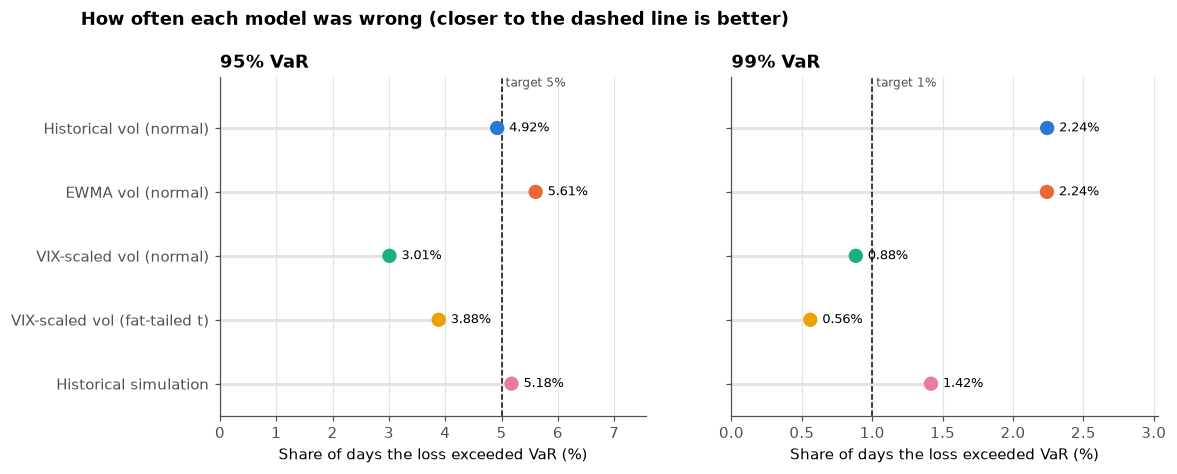

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
order = list(MODELS)
for ax, lv in zip(axes, LEVELS):
    s = summary[summary["level"] == lv].set_index("model").loc[order]
    y = np.arange(len(order))
    target = 100 * (1 - lv)
    ax.hlines(y, 0, s["breach_rate_pct"], color=GRID, lw=2)
    ax.scatter(s["breach_rate_pct"], y, s=70, color=[COLORS[m] for m in order], zorder=3)
    for yi, v in zip(y, s["breach_rate_pct"]):
        ax.text(v, yi, f"   {v:.2f}%", va="center", fontsize=8.5)
    ax.axvline(target, color=INK, ls="--", lw=1)
    ax.text(target, -0.6, f" target {target:.0f}%", fontsize=8, color=MUTED, va="bottom")
    ax.set_title(f"{int(lv * 100)}% VaR")
    ax.set_xlabel("Share of days the loss exceeded VaR (%)")
    ax.set_xlim(0, max(s["breach_rate_pct"].max(), target) * 1.35)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(np.arange(len(order)), [MODELS[m] for m in order])
axes[0].set_ylim(len(order) - 0.5, -0.8)
fig.suptitle("How often each model was wrong (closer to the dashed line is better)",
             x=0.01, y=1.03, ha="left", fontweight="bold")
save(fig, "results_1_breach_rates")

**What this tells us.**

* **At 99%, the backward-looking models break their promise.** Historical vol and EWMA were each breached on 2.24% of days, more than twice the 1% they promise. A quarter of the historical model's portfolio-years (26%) landed in the Basel **red** zone.
* **The VIX-scaled model comes closest to target** (0.88%). It has 88% of portfolio-years green and under 1% red, and the fewest bunched-up breaches (clustering rejected for 1% of portfolio-years against 13% for historical vol).
* **Adding fat tails on top over-corrects.** The fat-tailed VIX model was breached on only 0.56% of days. That is very safe (97% green, no red), but it pays for the safety with capital (§7.5).
* **At 95% the ranking flips.** Historical vol and historical simulation sit on target, while the VIX models are too cautious (3.0–3.9%). The VIX's built-in risk premium (§4.4) shows up most on ordinary bad days; in the extreme tail it is what keeps the model safe.
* **No model passes everywhere.** For every model, 20–40% of individual portfolio-years still fail the Kupiec test. A five-stock portfolio carries stock-specific shocks (earnings surprises, takeovers) that no market-wide volatility forecast can see.

### 7.3 When do models fail? Breach rates year by year

In [69]:
by_year = pd.DataFrame({m: (fc["realized"] < -fc[f"var99_{m}"]).groupby(fc["year"]).mean() * 100
                        for m in MODELS})
by_year.round(2).to_csv(RESULTS / "breach_rate_by_year_99.csv")
by_year.rename(columns=MODELS).round(2)

,Historical vol (normal),EWMA vol (normal),VIX-scaled vol (normal),VIX-scaled vol (fat-tailed t),Historical simulation
year,,,,,
2016,1.84,1.95,1.14,0.79,1.11
2017,0.71,1.67,0.27,0.15,0.46
2018,4.42,3.16,1.16,0.70,2.28
2019,1.49,2.03,1.35,0.78,0.61
2020,5.07,3.72,1.78,1.38,3.13
2021,0.65,2.06,0.11,0.03,0.59
2022,4.11,2.10,0.93,0.43,2.77
2023,0.42,1.58,0.72,0.46,0.37
2024,1.48,1.87,0.50,0.32,1.40


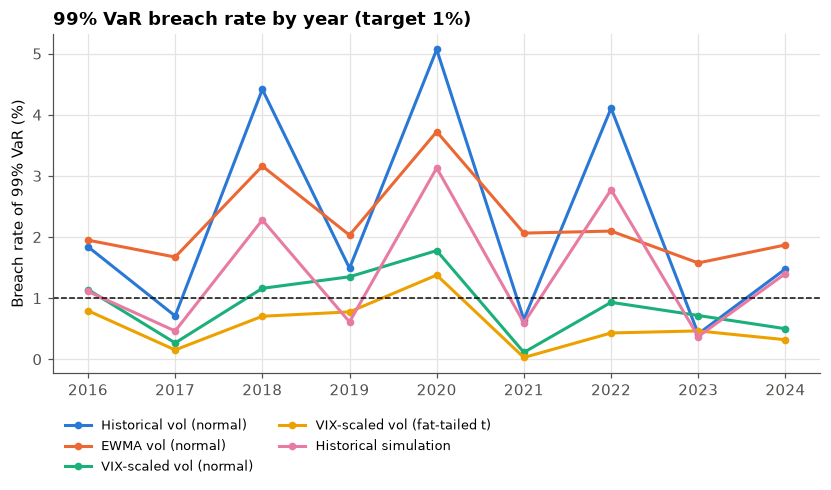

In [70]:
fig, ax = plt.subplots(figsize=(9, 4))
for m in MODELS:
    ax.plot(by_year.index, by_year[m], marker="o", ms=4, color=COLORS[m], label=MODELS[m])
ax.axhline(1, color=INK, ls="--", lw=1)
ax.set_xticks(by_year.index)
ax.set_ylabel("Breach rate of 99% VaR (%)")
ax.set_title("99% VaR breach rate by year (target 1%)")
ax.legend(fontsize=8.5, ncol=2, loc="upper left", bbox_to_anchor=(0, -0.1))
save(fig, "results_2_breaches_by_year")

**What this tells us.** The historical model's failures are concentrated in exactly the years that matter: **2018** (the February volatility spike and Q4 sell-off), **2020** (COVID) and **2022** (the rate-hike bear market), at 4–5× its target. In the calm years that follow (2021, 2023) it swings the other way, far *below* target, because its one-year memory still contains the storm. The VIX-scaled model stays between 0.1% and 1.8% in every year. In **March 2020** alone, the historical model was breached on 34% of portfolio-days, against 12% for the VIX-scaled model. Every model failed that month, but by very different amounts.

### 7.4 One portfolio through 2020

The dots are the portfolio's actual daily returns; the lines are each model's 99% VaR (the forecast loss limit). Circled dots are days the historical-vol model was breached.

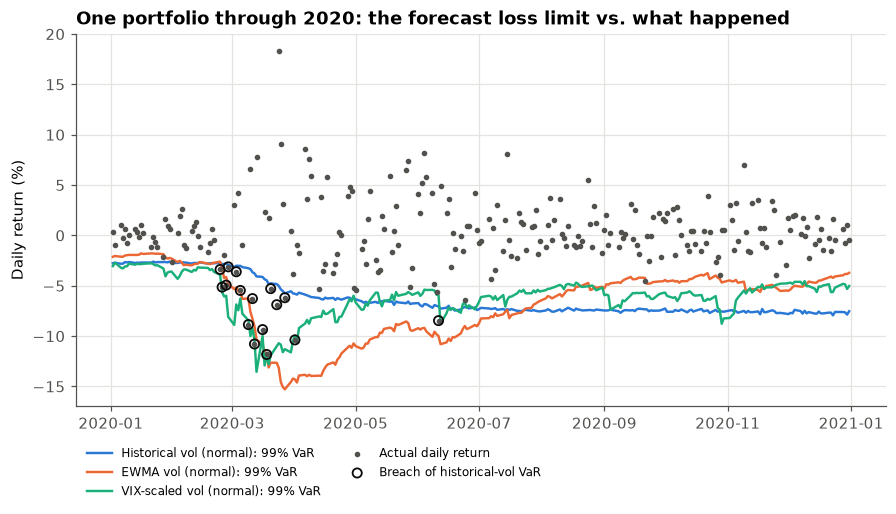

In [71]:
example = fc[(fc["year"] == 2020) & (fc["portfolio"] == 0)]

fig, ax = plt.subplots(figsize=(9.5, 4.4))
for m in ("hist", "ewma", "vix"):
    ax.plot(example["date"], -100 * example[f"var99_{m}"], color=COLORS[m], lw=1.6, label=f"{MODELS[m]}: 99% VaR")
ax.scatter(example["date"], 100 * example["realized"], s=7, color=MUTED, label="Actual daily return", zorder=3)
missed = example["realized"] < -example["var99_hist"]
ax.scatter(example["date"][missed], 100 * example["realized"][missed], s=36, facecolor="none",
           edgecolor=INK, lw=1.2, zorder=4, label="Breach of historical-vol VaR")
ax.set_ylabel("Daily return (%)")
ax.set_title("One portfolio through 2020: the forecast loss limit vs. what happened")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=2)
save(fig, "results_3_example_2020")

### 7.5 Capital vs. accuracy

A model can always cut breaches by forecasting huge losses, but then it ties up capital for nothing. The ideal model sits on the target line using the **least** capital.

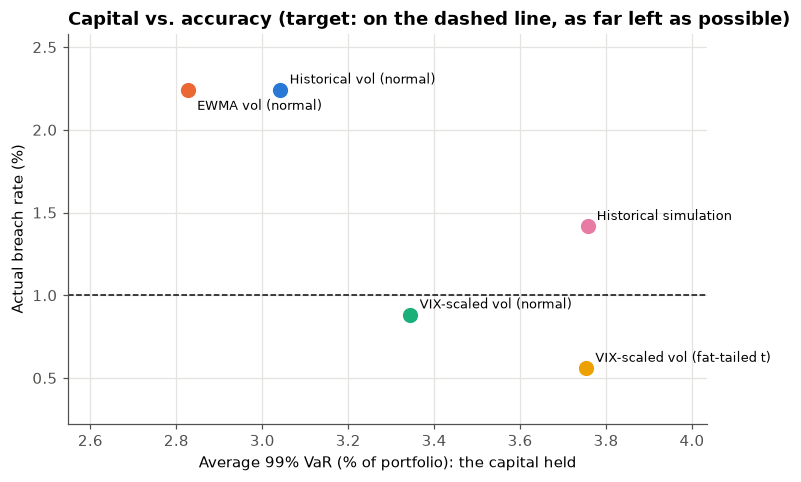

In [72]:
s99 = summary[summary["level"] == 0.99].set_index("model")

fig, ax = plt.subplots(figsize=(7.5, 4.6))
for m in MODELS:
    x, y = s99.loc[m, "avg_var_pct"], s99.loc[m, "breach_rate_pct"]
    ax.scatter(x, y, s=80, color=COLORS[m], zorder=3)
    offset = (6, -13) if m == "ewma" else (6, 4)      # keep the two left-hand labels apart
    ax.annotate(MODELS[m], (x, y), xytext=offset, textcoords="offset points", fontsize=8.5)
ax.axhline(1, color=INK, ls="--", lw=1)
ax.margins(x=0.3, y=0.2)
ax.set_xlabel("Average 99% VaR (% of portfolio): the capital held")
ax.set_ylabel("Actual breach rate (%)")
ax.set_title("Capital vs. accuracy (target: on the dashed line, as far left as possible)")
save(fig, "results_4_capital_vs_accuracy")

In [73]:
relative = 100 * (s99["avg_var_pct"] / s99.loc["hist", "avg_var_pct"] - 1)
relative.rename(index=MODELS).round(1).to_frame("Capital vs. historical-vol model (%)")

,Capital vs. historical-vol model (%)
model,
Historical vol (normal),0.0
EWMA vol (normal),-7.1
VIX-scaled vol (normal),9.9
VIX-scaled vol (fat-tailed t),23.4
Historical simulation,23.5


**What this tells us.** The VIX-scaled model holds about **10% more capital** on average than the historical model, but cuts the 99% breach rate by more than half (2.24% to 0.88%) and red-zone portfolio-years from 26% to under 1%. Historical simulation holds 23% more capital and is still above target. EWMA is the cheapest, because it forgets past storms fastest, but it is breached as often as the historical model. Of the five, the VIX-scaled model gives the best trade-off, and it has the lowest quantile loss, the single score that balances both.

## 8. Is the simulation itself accurate?

A Monte Carlo answer is an *estimate*: rerun with different random numbers and it changes slightly. Here we measure that noise and two ways of reducing it, using the walk-through portfolio from §5 (VIX-scaled model, 99% level).

* **Convergence.** Rerun the simulation many times at each path count. The spread of answers (standard error) should shrink like $1/\sqrt{N}$: four times the paths for half the error.
* **Antithetic variates.** Pair every scenario *z* with its mirror image −*z*. This is very effective for estimating *averages*, but the tail of a symmetric distribution and its mirror image don't overlap, so we expect little gain for VaR.
* **Importance sampling.** Only ~1% of plain scenarios land in the tail we care about. Importance sampling deliberately shifts the random draws toward losses, so many more scenarios land in the tail, then re-weights each by its likelihood ratio so the answer stays unbiased.

### 8.1 Three estimators

In [74]:
chol_demo = np.linalg.cholesky(cov_v[0])
w_demo = np.full(N_STOCKS, 1 / N_STOCKS)


def estimate_plain(rng, n_paths, level=0.99, antithetic=False):
    port = simulate(chol_demo[None], normal_shocks(rng, n_paths, N_STOCKS, antithetic))
    v, e = var_es(port, level)
    return v[0], e[0]

In [75]:
def estimate_importance(rng, n_paths, level=0.99):
    # 1. shift the shocks toward the direction in which the portfolio loses most
    direction = chol_demo.T @ w_demo
    shift = -stats.norm.ppf(level) * direction / np.linalg.norm(direction)
    z = rng.standard_normal((n_paths, N_STOCKS)) + shift
    # 2. weight each scenario by how much more likely it was made by the shift
    weight = np.exp(-z @ shift + 0.5 * shift @ shift) / n_paths
    # 3. weighted VaR and ES
    port = simulate(chol_demo[None], z)[0]
    order = np.argsort(port)
    port, weight = port[order], weight[order]
    k = np.searchsorted(np.cumsum(weight), 1 - level)
    return -port[k], -(weight[:k + 1] * port[:k + 1]).sum() / (1 - level)

A very large run (4 million paths) serves as the "true" answer:

In [76]:
ref_var, ref_es = estimate_plain(np.random.default_rng(99), 4_000_000, antithetic=True)
print(f"Reference: 99% VaR {100 * ref_var:.3f}%, 99% ES {100 * ref_es:.3f}%")

Reference: 99% VaR 2.525%, 99% ES 2.891%


### 8.2 Convergence

For each path count, repeat the estimate many times and measure how much the answers spread.

In [77]:
rng_conv = np.random.default_rng(2)
conv_rows = []
for n_paths in (1_000, 3_000, 10_000, 30_000, 100_000, 300_000, 1_000_000):
    reps = 300 if n_paths <= 30_000 else (60 if n_paths <= 300_000 else 20)
    est = np.array([estimate_plain(rng_conv, n_paths) for _ in range(reps)])
    conv_rows.append({"paths": n_paths, "reps": reps,
                      "var_mean_pct": 100 * est[:, 0].mean(), "var_se_pct": 100 * est[:, 0].std(ddof=1),
                      "es_mean_pct": 100 * est[:, 1].mean(), "es_se_pct": 100 * est[:, 1].std(ddof=1)})
conv = pd.DataFrame(conv_rows)
conv.to_csv(RESULTS / "mc_convergence.csv", index=False)
conv.round(4)

,paths,reps,var_mean_pct,var_se_pct,es_mean_pct,es_se_pct
0,1000,300,2.5038,0.1363,2.8307,0.1577
1,3000,300,2.5230,0.0755,2.8803,0.0889
2,10000,300,2.5221,0.0410,2.8797,0.0494
3,30000,300,2.5266,0.0247,2.8882,0.0292
4,100000,60,2.5281,0.0139,2.8907,0.0187
5,300000,60,2.5251,0.0065,2.8869,0.0079
6,1000000,20,2.5263,0.0035,2.8894,0.0047


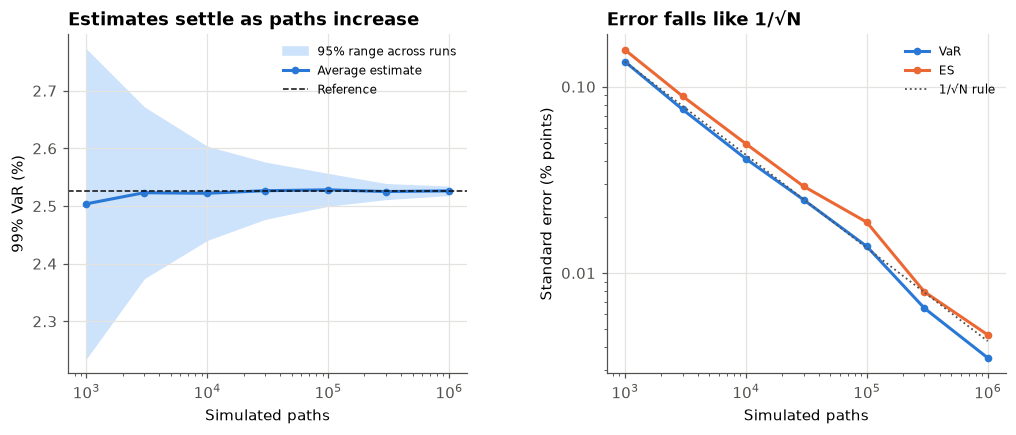

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"wspace": 0.35})

ax = axes[0]
ax.fill_between(conv["paths"], conv["var_mean_pct"] - 1.96 * conv["var_se_pct"],
                conv["var_mean_pct"] + 1.96 * conv["var_se_pct"], color="#cde2fb", label="95% range across runs")
ax.plot(conv["paths"], conv["var_mean_pct"], color=COLORS["hist"], marker="o", ms=4, label="Average estimate")
ax.axhline(100 * ref_var, color=INK, ls="--", lw=1, label="Reference")
ax.set_xscale("log")
ax.set_xlabel("Simulated paths")
ax.set_ylabel("99% VaR (%)")
ax.set_title("Estimates settle as paths increase")
ax.legend(fontsize=8)

ax = axes[1]
ax.loglog(conv["paths"], conv["var_se_pct"], color=COLORS["hist"], marker="o", ms=4, label="VaR")
ax.loglog(conv["paths"], conv["es_se_pct"], color=COLORS["ewma"], marker="o", ms=4, label="ES")
ax.loglog(conv["paths"], conv["var_se_pct"].iloc[0] * np.sqrt(1_000 / conv["paths"]),
          color=MUTED, ls=":", lw=1.2, label="1/√N rule")
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_xlabel("Simulated paths")
ax.set_ylabel("Standard error (% points)")
ax.set_title("Error falls like 1/√N")
ax.legend(fontsize=8)
save(fig, "mc_1_convergence")

In [79]:
at_10k = conv.set_index("paths").loc[10_000]
print(f"At 10,000 paths (used in the backtest): 99% VaR standard error = {at_10k['var_se_pct']:.3f} "
      f"percentage points, ES = {at_10k['es_se_pct']:.3f}")

At 10,000 paths (used in the backtest): 99% VaR standard error = 0.041 percentage points, ES = 0.049


### 8.3 Variance reduction

All three estimators use 10,000 paths, repeated 400 times. A variance reduction of *k*× means the method matches plain Monte Carlo's accuracy with *k* times fewer paths.

In [80]:
methods = {
    "Plain Monte Carlo": lambda r: estimate_plain(r, 10_000),
    "Antithetic variates": lambda r: estimate_plain(r, 10_000, antithetic=True),
    "Importance sampling": lambda r: estimate_importance(r, 10_000),
}
vr_rows = []
for name, estimator in methods.items():
    rng_vr = np.random.default_rng(3)
    tic = time.perf_counter()
    est = np.array([estimator(rng_vr) for _ in range(400)])
    vr_rows.append({"method": name,
                    "var_mean_pct": 100 * est[:, 0].mean(), "var_se_pct": 100 * est[:, 0].std(ddof=1),
                    "es_mean_pct": 100 * est[:, 1].mean(), "es_se_pct": 100 * est[:, 1].std(ddof=1),
                    "ms_per_run": 1000 * (time.perf_counter() - tic) / 400})
vr = pd.DataFrame(vr_rows).set_index("method")

In [81]:
vr["var_variance_reduction"] = (vr["var_se_pct"].iloc[0] / vr["var_se_pct"]) ** 2
vr["es_variance_reduction"] = (vr["es_se_pct"].iloc[0] / vr["es_se_pct"]) ** 2
vr.round(4).to_csv(RESULTS / "mc_variance_reduction.csv")
vr.round(4)

,var_mean_pct,var_se_pct,es_mean_pct,es_se_pct,ms_per_run,var_variance_reduction,es_variance_reduction
method,,,,,,,
Plain Monte Carlo,2.5248,0.0396,2.8824,0.0468,0.4092,1.0000,1.0000
Antithetic variates,2.5237,0.0406,2.8839,0.0457,0.3303,0.9533,1.0515
Importance sampling,2.5263,0.0066,2.8894,0.0045,1.0279,35.7948,107.0310


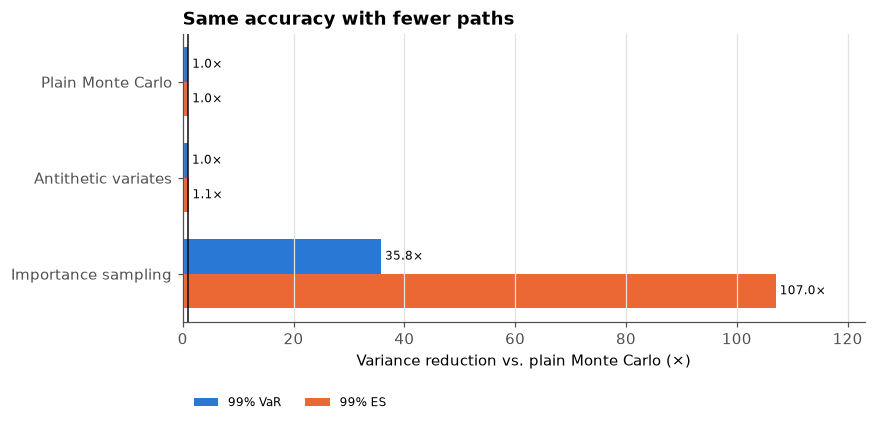

In [82]:
fig, ax = plt.subplots(figsize=(8, 3.4))
y, h = np.arange(len(vr)), 0.36
ax.barh(y - h / 2, vr["var_variance_reduction"], h, color=COLORS["hist"], label="99% VaR")
ax.barh(y + h / 2, vr["es_variance_reduction"], h, color=COLORS["ewma"], label="99% ES")
for yi, a, b in zip(y, vr["var_variance_reduction"], vr["es_variance_reduction"]):
    ax.text(a, yi - h / 2, f" {a:.1f}×", va="center", fontsize=8)
    ax.text(b, yi + h / 2, f" {b:.1f}×", va="center", fontsize=8)
ax.set_yticks(y, vr.index)
ax.set_ylim(len(vr) - 0.5, -0.5)
ax.axvline(1, color=INK, lw=1)
ax.set_xlabel("Variance reduction vs. plain Monte Carlo (×)")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, vr[["var_variance_reduction", "es_variance_reduction"]].max().max() * 1.15)
ax.set_title("Same accuracy with fewer paths")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.22), ncol=2)
save(fig, "mc_2_variance_reduction")

**What this tells us.** As expected, antithetic variates barely help in the tail. Importance sampling, which concentrates effort where the risk is, gives a large improvement for both VaR and ES. That makes it the right tool for production-scale risk systems.

## 9. Conclusions

*The full interpretation of these results, written for a non-technical reader, is in [`docs/report.md`](../docs/report.md).*

**Key findings**

1. **The course version's headline was an artefact.** Its multiplier (VIX ÷ average single-stock volatility, 0.60 on average) was below the like-for-like one (VIX ÷ index volatility, 1.16) on every single date. Options were on average pricing *more* risk than the past year showed, not half as much.
2. **Forward-looking beats backward-looking where it counts.** At 99%, the VIX-scaled model was breached on 0.88% of days (target 1%), against 2.24% for historical vol. Its red-zone portfolio-years fell from 26% to under 1%, for about 10% more capital.
3. **Backward-looking models fail in the turning points.** Historical vol was breached 4–5× too often in 2018, 2020 and 2022 (34% of days in March 2020), then too rarely in the calm years after.
4. **Fat tails are real** (moves beyond 4σ are about 100× more common than a bell curve predicts), but adding a Student-t on top of the VIX premium over-corrects (0.56% breaches).
5. **The simulation is accurate and efficient.** At 10,000 paths the 99% VaR has a standard error of 0.04 percentage points. Importance sampling cuts the variance 36× for VaR and 107× for ES; antithetic variates give no gain in the tail, as theory predicts.

**Limitations**
* **Correlations come from the past year**, but §4.6 shows they jump in crises. All models therefore under-react to sudden "everything falls together" days.
* **Equal-weight five-stock portfolios** make a demanding but stylised test. Real portfolios are larger and actively weighted.
* **One-day horizon only.** Regulatory capital uses 10-day horizons, where volatility dynamics matter even more.
* **The VIX is market-wide.** It scales every stock's volatility by the same factor, so stock-specific news (an earnings surprise, a lawsuit) is not captured. Stock-level implied volatility from OptionMetrics, not part of this WRDS subscription, is the natural refinement.
* **The VIX includes a risk premium** (§4.4), so VIX-based models lean conservative unless the premium is removed.

**Natural next steps:** use stock-level implied volatility (OptionMetrics), forecast correlations as well (e.g. a DCC-GARCH model), test a filtered historical simulation, extend to 10-day horizons, and use importance sampling inside the backtest itself.